# Normalization Check for build_loaders_from_hf

This notebook loads and verifies whether normalization was applied to the image tensors. Means close to 0 and stds close to 1 per channel indicate successful normalization.

In [1]:
from typing import Tuple, Iterable, Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from framework.dataset.load_for_training import load_hf_splits, build_loaders_from_hf

/Users/ricostadeli/Documents/HSG/DeepLearning/R-L-Net/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def compute_channel_stats(loader: torch.utils.data.DataLoader, num_batches: int = 5):
    means, vars_ = [], []
    processed = 0
    for batch in loader:
        x = batch[0] if isinstance(batch, (tuple, list)) else (
            batch.get('pixel_values') if isinstance(batch, dict) else batch)
        if isinstance(x, (list, tuple)):
            x = x[0]
        x = torch.as_tensor(x)
        if x.ndim == 3:
            x = x.unsqueeze(0)
        B, C, H, W = x.shape
        x = x.float().reshape(B, C, -1)
        means.append(x.mean(dim=(0, 2)).cpu().numpy())
        vars_.append(x.var(dim=(0, 2), unbiased=False).cpu().numpy())
        processed += 1
        if processed >= num_batches:
            break
    means = np.stack(means).mean(axis=0)
    stds = np.sqrt(np.stack(vars_).mean(axis=0))
    return means, stds



def _coerce_name_loader_items(obj) -> Iterable[Tuple[str, Any]]:
    # Dict case
    if isinstance(obj, dict):
        return obj.items()

    # List/tuple of (name, loader) pairs
    if isinstance(obj, (list, tuple)) and len(obj) > 0:
        if all(isinstance(x, tuple) and len(x) == 2 for x in obj):
            return obj
        # Plain sequence of loaders
        names = ["train", "val", "test", "extra1", "extra2"]
        return [(names[i], obj[i]) for i in range(min(len(obj), len(names)))]

    # Single loader
    return [("loader", obj)]

def _ensure_dataloader(maybe_loader):
    # If it already looks like a DataLoader, keep it
    if hasattr(maybe_loader, "__iter__") and hasattr(maybe_loader, "batch_size"):
        return maybe_loader

    # If it looks like a Dataset, wrap it
    if hasattr(maybe_loader, "__len__") and hasattr(maybe_loader, "__getitem__"):
        from torch.utils.data import DataLoader
        return DataLoader(maybe_loader, batch_size=32, shuffle=False)

    return maybe_loader  # best effort

def check_normalization_for_loaders(loaders, num_batches: int = 5) -> pd.DataFrame:
    rows = []
    for name, loader in _coerce_name_loader_items(loaders):
        try:
            loader = _ensure_dataloader(loader)
            means, stds = compute_channel_stats(loader, num_batches=num_batches)
            row = {"loader": name}
            for i, m in enumerate(means):
                row[f"mean_c{i}"] = float(m)
            for i, s in enumerate(stds):
                row[f"std_c{i}"] = float(s)
            rows.append(row)
        except Exception as e:
            rows.append({"loader": name, "error": str(e)})
    df = pd.DataFrame(rows)
    display(df)
    return df


def plot_means_stds(means: np.ndarray, stds: np.ndarray, title_prefix: str):
    s_means = pd.Series(means, index=[f'c{i}' for i in range(len(means))])
    s_stds = pd.Series(stds, index=[f'c{i}' for i in range(len(stds))])
    plt.figure();
    s_means.plot(kind='bar');
    plt.title(f'{title_prefix} - per channel mean');
    plt.xlabel('Channel');
    plt.ylabel('Value');
    plt.show()
    plt.figure();
    s_stds.plot(kind='bar');
    plt.title(f'{title_prefix} - per channel std');
    plt.xlabel('Channel');
    plt.ylabel('Value');
    plt.show()

## Check for EuroSAT dataset

In [3]:
dataset_hf_repo_id = "blanchon/EuroSAT_MSI"
batch_size = 256
image_size = 64
calculated_indices = ["NDVI", "NDWI", "NDMI"]
augment = False
normalize = True
selected_bands = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]
num_workers = 0
pin_memory = False

train_ds, val_ds, test_ds = load_hf_splits(dataset_hf_repo_id)
loaders = build_loaders_from_hf(train_ds, val_ds,
                                batch_size,
                                image_size,
                                calculated_indices,
                                augment,
                                normalize=normalize,
                                stats_samples=0,
                                selected_bands=selected_bands,
                                num_workers=num_workers,
                                pin_memory=pin_memory)

Calculating mean and std for 64 batches for Training Dataset before Normalization: 100%|██████████| 64/64 [00:43<00:00,  1.48it/s]


,loader,mean_c0,mean_c1,mean_c2,mean_c3,mean_c4,mean_c5,mean_c6,mean_c7,mean_c8,...,std_c5,std_c6,std_c7,std_c8,std_c9,std_c10,std_c11,std_c12,std_c13,std_c14
0,train,-0.027567,-0.028621,-0.029806,-0.024434,-0.019420,-0.005339,-0.002083,-0.001251,0.009329,...,0.999818,0.998693,0.996269,1.008949,0.993867,0.980910,0.997792,0.999932,1.001842,0.982969
1,val,-0.354627,-0.238057,-0.130335,-0.058288,0.040673,0.422597,0.496353,0.476685,0.245622,...,0.679432,0.712457,0.702899,0.837638,0.790297,0.879579,0.679822,0.630723,0.412330,0.866813


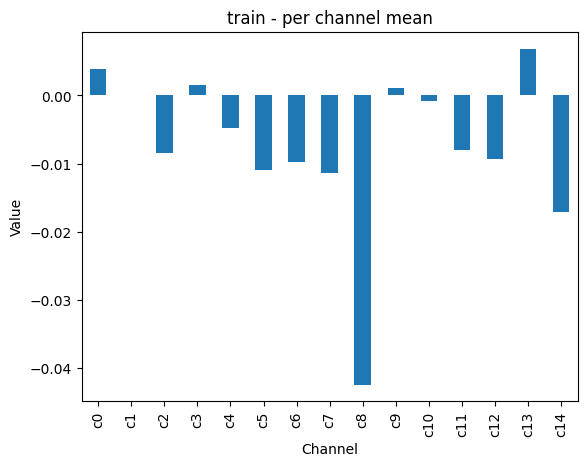

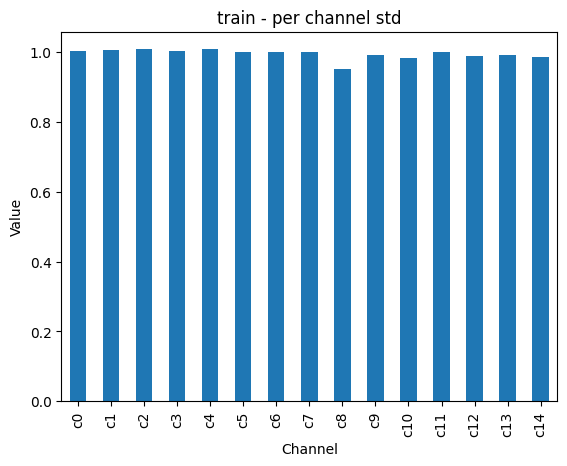

In [4]:
df = check_normalization_for_loaders(loaders, num_batches=5)

first_name, first_loader = next(iter(_coerce_name_loader_items(loaders)))
means, stds = compute_channel_stats(_ensure_dataloader(first_loader), num_batches=5)
plot_means_stds(means, stds, title_prefix=first_name)

## Check for Resisc45 dataset

In [5]:
dataset_hf_repo_id = "timm/resisc45"
batch_size = 256
image_size = 256
calculated_indices = []
augment = False
normalize = True
selected_bands = ["B01", "B02", "B03"]
num_workers = 0
pin_memory = False

train_ds, val_ds, test_ds = load_hf_splits(dataset_hf_repo_id)
loaders = build_loaders_from_hf(train_ds, val_ds,
                                batch_size,
                                image_size,
                                calculated_indices,
                                augment,
                                normalize=normalize,
                                stats_samples=0,
                                selected_bands=selected_bands,
                                num_workers=num_workers,
                                pin_memory=pin_memory)

Calculating mean and std for 74 batches for Training Dataset before Normalization: 100%|██████████| 74/74 [00:09<00:00,  7.46it/s]


,loader,mean_c0,mean_c1,mean_c2,std_c0,std_c1,std_c2
0,train,0.000543,-0.001300,-0.001849,0.987268,0.986609,0.986431
1,val,-0.033297,-0.033585,-0.033482,0.988821,0.990881,0.991144


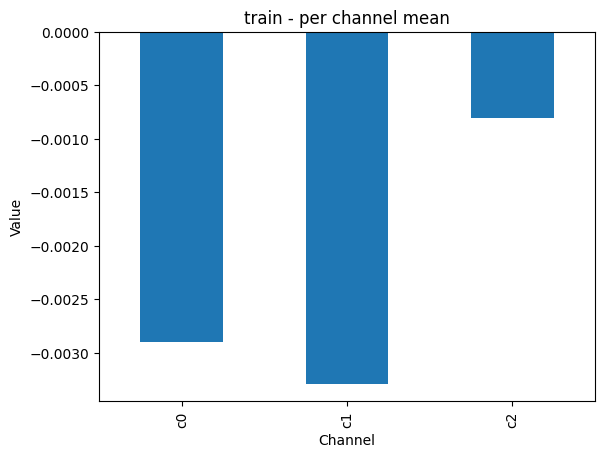

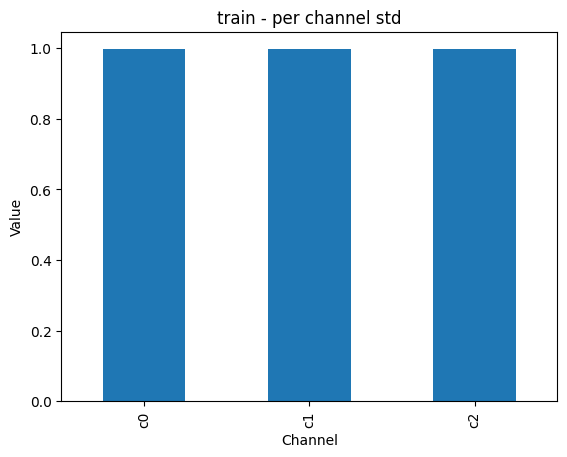

In [6]:
df = check_normalization_for_loaders(loaders, num_batches=5)

first_name, first_loader = next(iter(_coerce_name_loader_items(loaders)))
means, stds = compute_channel_stats(_ensure_dataloader(first_loader), num_batches=5)
plot_means_stds(means, stds, title_prefix=first_name)